In [1]:
import os
import dotenv
from google import genai
from google.genai import types
from typing import List
from sklearn.metrics.pairwise import cosine_similarity
from rag_tutorial.vector_embeddings_plots import plot_similarity_matrix
from langchain_openai import OpenAIEmbeddings
from pydantic import SecretStr

dotenv.load_dotenv()

True

- google gemini embeddings
- compute similarities using cosine similarity
- openai embeddings


In [2]:
# Configure Gemini
client = genai.Client(api_key=os.getenv("GOOGLE_API_KEY"))

In [3]:
api_key = SecretStr(os.getenv("OPENROUTER_API_KEY", ""))
if not api_key.get_secret_value():
    raise RuntimeError("OPENROUTER_API_KEY is not set")

openai_client = OpenAIEmbeddings(
    api_key=api_key,
    base_url="https://openrouter.ai/api/v1",
    model="openai/text-embedding-3-small"
)

In [4]:
# Get embedding for text using Gemini
def get_embedding(
    text: str,
    model_name: str = "gemini-embedding-001",
    task_type: str = "RETRIEVAL_DOCUMENT",  # "RETRIEVAL_QUERY" for queries
) -> list[float]:
    """Get embedding for a single text using Gemini"""
    result = client.models.embed_content(
        model=model_name,
        contents=text,
        config=types.EmbedContentConfig(task_type=task_type),
    )
    assert result.embeddings and result.embeddings[0].values is not None
    return list(result.embeddings[0].values)
   

In [5]:
# Get embeddings for multiple texts
def get_embeddings_batch(
    texts: list[str],
    model_name: str = "gemini-embedding-001",
    task_type: str = "RETRIEVAL_DOCUMENT",
) -> list[list[float]]:
    """Get embeddings for multiple texts in a single request"""
    result = client.models.embed_content(
        model=model_name,
        contents=texts,
        config=types.EmbedContentConfig(task_type=task_type),
    )
    assert result.embeddings is not None
    return [list(e.values) for e in result.embeddings if e.values is not None]


In [6]:
#Example usage
text = "Machine learning is a subset of artificial intelligence"
embedding = get_embedding(text)

print(f"Text: {text}")
print(f"Embedding dimension: {len(embedding)}")
print(f"First 10 values: {embedding[:10]}")


Text: Machine learning is a subset of artificial intelligence
Embedding dimension: 3072
First 10 values: [-0.02326879, 0.005238002, -0.0053982376, -0.06831077, -0.014663871, 0.005497276, 0.0006220974, 0.009017719, 0.0072250613, -0.004619009]


In [7]:
# Batch processing
texts = [
    "Python is a programming language",
    "Python is a type of snake",
    "JavaScript is used for web development",
    "Coffee is a popular beverage"
]

In [8]:
gemini_embeddings = get_embeddings_batch(texts)
print(f"\nGenerated {len(gemini_embeddings)} embeddings")
print(f"First embedding length: {len(gemini_embeddings[0])}")
print(f"Second embedding length: {len(gemini_embeddings[1])}") 
""" print first  10 values for each embedding text"""
for i, emb in enumerate(gemini_embeddings):
    print(f"Embedding {i} first 10: {emb[:10]}")


Generated 4 embeddings
First embedding length: 3072
Second embedding length: 3072
Embedding 0 first 10: [-0.004513293, 0.002469157, -0.0014089564, -0.078670524, -0.013966714, 0.0138775, 0.0025203268, 0.007443929, 0.017795688, -0.0013496545]
Embedding 1 first 10: [-0.011284315, 0.006662989, 0.007784657, -0.070202656, -0.0034702625, 0.014956395, 0.00922638, 0.006548303, 0.007317398, -0.009715795]
Embedding 2 first 10: [-0.00924809, -0.010532121, -0.008529407, -0.07870253, -0.008442616, 0.023183046, 0.020481177, 0.0051697134, 0.0050863917, -0.0196881]
Embedding 3 first 10: [-0.011724939, 0.0093832845, 0.025369866, -0.06626642, -0.0056614485, 0.018658498, -0.01795365, 0.0072820885, -0.0011454419, -0.0005937814]


In [9]:
""" cosine similarity for vectors """
from numpy import dot
from numpy.linalg import norm
def cosine_similarity_(a, b):
    return dot(a, b) / (norm(a) * norm(b))

In [10]:
cosine_similarity_([1,0],[0,1])

np.float64(0.0)

In [11]:
similarities = cosine_similarity(gemini_embeddings)
similarities

array([[1.        , 0.90968953, 0.83518792, 0.76791681],
       [0.90968953, 1.        , 0.78207702, 0.75052282],
       [0.83518792, 0.78207702, 1.        , 0.77270979],
       [0.76791681, 0.75052282, 0.77270979, 1.        ]])

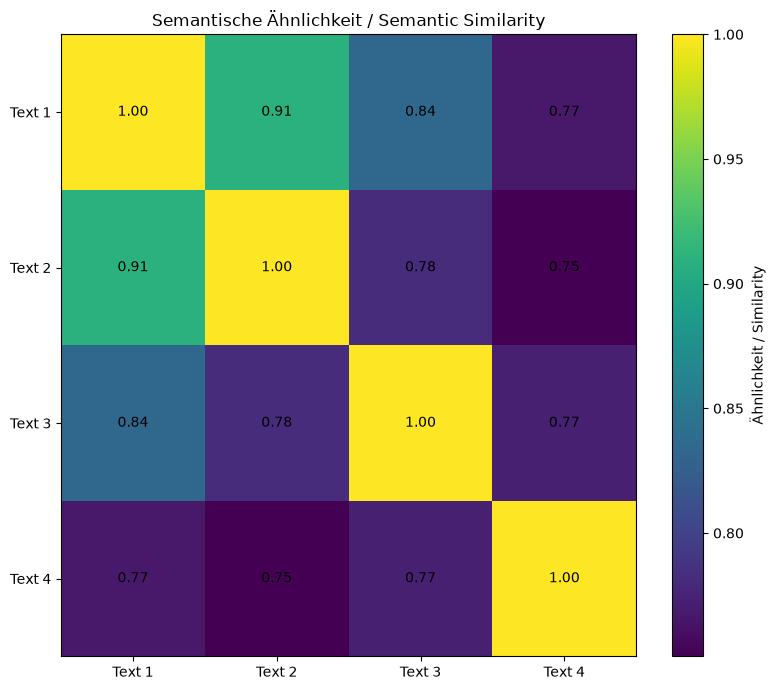

In [12]:
plot_similarity_matrix(similarities, texts)

In [13]:
openai_embeddings_list = openai_client.embed_documents(texts)
similarities = cosine_similarity(openai_embeddings_list)
similarities

array([[1.        , 0.68118041, 0.32884857, 0.12793595],
       [0.68118041, 1.        , 0.23403407, 0.07306256],
       [0.32884857, 0.23403407, 1.        , 0.18026925],
       [0.12793595, 0.07306256, 0.18026925, 1.        ]])

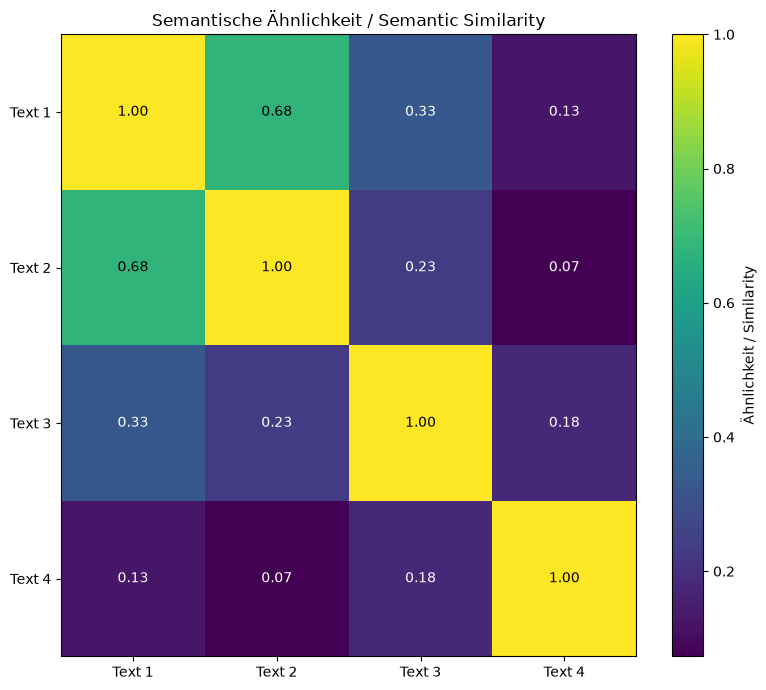

In [14]:
plot_similarity_matrix(similarities, texts)

In [15]:
# Compare embedding approaches
text = "The quick brown fox jumps over the lazy dog"


In [16]:
# Gemini embedding
gemini_embedding = get_embedding(text, model_name="gemini-embedding-001")

In [17]:
openai_embeddings = openai_client.embed_query(text) # get embedding for text

In [18]:
# Alternative: Using Sentence Transformers (open source)
from sentence_transformers import SentenceTransformer
st_model = SentenceTransformer('all-MiniLM-L6-v2')
st_embedding = st_model.encode(text)

c:\Artificial Intelligence\rag_tutorial\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7924.09it/s]


In [19]:
import numpy as np

In [20]:
# Compare results
comparison = {
    "Gemini": {
        "dimensions": len(gemini_embedding),
        "sample_values": gemini_embedding[:5],
        "magnitude": np.linalg.norm(gemini_embedding)
    },
    "OpenAI": {
            "dimensions": len(openai_embeddings),
            "sample_values": openai_embeddings[:5],
            "magnitude": np.linalg.norm(openai_embeddings)
        },
    "Sentence-Transformers": {
        "dimensions": len(st_embedding),
        "sample_values": st_embedding[:5].tolist(),
        "magnitude": np.linalg.norm(st_embedding)
    }
}

In [21]:
# Display comparison
for model, info in comparison.items():
    print(f"\nModel: {model}")
    print(f"Dimensions: {info['dimensions']}")
    print(f"Magnitude: {info['magnitude']:.4f}")
    print(f"Sample: {[f'{v:.4f}' for v in info['sample_values']]}")


Model: Gemini
Dimensions: 3072
Magnitude: 1.0000
Sample: ['-0.0147', '0.0224', '0.0055', '-0.0766', '0.0019']

Model: OpenAI
Dimensions: 1536
Magnitude: 1.0003
Sample: ['-0.0208', '-0.0169', '-0.0045', '-0.0509', '-0.0260']

Model: Sentence-Transformers
Dimensions: 384
Magnitude: 1.0000
Sample: ['0.0355', '0.0613', '0.0527', '0.0707', '0.0331']
